## **Shallow water equations**

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:

#IMPORT LIBRARIES

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sys
import cmcrameri.cm as cmc
import pandas as pd

from the_well.data import WellDataset

# Add parent directory to path to access src module
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent.parent))
print("Current working directory:", Path.cwd())
print("Parent directory added to path:", Path.cwd().parent.parent)

# Importing modules from src
from src.datamanager import ROMDataManager, DataManager
from src.engine import SHREDEngine
from src.train import fit
from src.mSHRED.mSHRED import mSHRED

from helper import plot_shred_reconstruction_multi, plot_overview_and_availability
from types import SimpleNamespace

# get device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

Current working directory: /home/matteo/Documents/Masked-SHRED/Notebooks/SWE
Parent directory added to path: /home/matteo/Documents/Masked-SHRED


## Data Load

In [3]:
# ONLY RUN THIS ONCE TO DOWNLOAD THE DATASET
#well_download(base_path="", dataset="planetswe", split="train", first_only=True)

# LOAD THE DATASET
data_folder = "datasets"
dataset = WellDataset(
    well_base_path = data_folder,
    well_dataset_name = "planetswe",
    well_split_name = "train",
    n_steps_input = 1008,
    n_steps_output = 0,
    use_normalization = False,
)
#I've downloaded 0 and 1, you can change this to load the other ones
dataset = dataset[0] 

# BUILD SNAPSHOTS MATRICES

theta = dataset["space_grid"][:,:,0]    # theta: colatitude angle (radians) at each grid point, shape (Lx, Ly)
phi = dataset["space_grid"][:,:,1]      # phi: longitude angle (radians) at each grid point, shape (Lx, Ly)

print("theta shape:\t", theta.shape)
print("phi shape:\t", phi.shape)

ntimes, Lx, Ly, _ = dataset['input_fields'].shape   # ntimes: number of time steps, Lx: number of grid points in x (colatitude), Ly: number of grid points in y (longitude)
nheight = nvelocity = Lx * Ly                       # total number of spatial grid points (flattened)

print("ntimes:\t\t", ntimes)    
print("Lx:\t\t", Lx)            
print("Ly:\t\t", Ly)            
print("nheight:\t", nheight)
print("nvelocity:\t", nvelocity)

H = dataset["input_fields"][:,:,:,0].reshape(ntimes, nheight)           # H: snapshot matrix of height deviation h(x,t), shape (ntimes, nheight)
Utheta = dataset["input_fields"][:,:,:,1].reshape(ntimes, nvelocity)    # Utheta: snapshot matrix of velocity component along colatitude, shape (ntimes, nvelocity)
Uphi = dataset["input_fields"][:,:,:,2].reshape(ntimes, nvelocity)      # Uphi: snapshot matrix of velocity component along longitude, shape (ntimes, nvelocity)

print("H shape:\t", H.shape)
print("Utheta shape:\t", Utheta.shape)
print("Uphi shape:\t", Uphi.shape)

# DELETE DATASET TO FREE UP MEMORY

del dataset

theta shape:	 torch.Size([256, 512])
phi shape:	 torch.Size([256, 512])
ntimes:		 1008
Lx:		 256
Ly:		 512
nheight:	 131072
nvelocity:	 131072
H shape:	 torch.Size([1008, 131072])
Utheta shape:	 torch.Size([1008, 131072])
Uphi shape:	 torch.Size([1008, 131072])


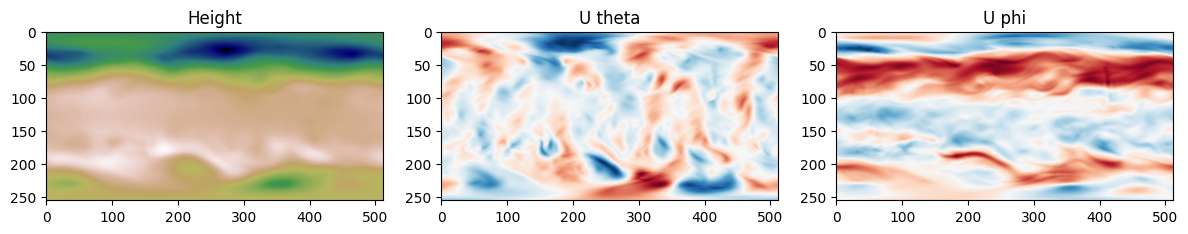

In [4]:
# Define a function to plot the state of the system at a given time step
def plot_state(u, cmap = "RdBu_r"):
    fig = plt.imshow(u.reshape(Lx, Ly), cmap = cmap)

plot_height = lambda u: plot_state(u, cmap = "gist_earth")
plot_velocity = lambda u: plot_state(u, cmap = "RdBu_r")

# Plot the state of the system at the first time step
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plot_height(H[0])
plt.title("Height")
plt.subplot(1, 3, 2)
plot_velocity(Utheta[0])
plt.title("U theta")
plt.subplot(1, 3, 3)        
plot_velocity(Uphi[0])
plt.title("U phi")
plt.tight_layout()
plt.show()

## SENSOR extraction

In [5]:
# EXTRACT SENSORS DATA 

# We randomly select 10 sensors on the grid and extract their time series data from the height field H. 
nsensors = 10
sensors_coordinates = np.vstack((np.random.choice(Lx, size = nsensors, replace = True), np.random.choice(Ly, size = nsensors, replace = True))).T
sensors_data = H.reshape(ntimes, Lx, Ly)[:,sensors_coordinates[:,0], sensors_coordinates[:,1]]
print("Sensors coordinates:\n", sensors_coordinates)
print("Sensors data shape:\t", sensors_data.shape)

# BROKEN SENSORS SIMULATION
# short broken : random Bernoulli drops
# long broken  : contiguous outage interval

short_broken = 4   # number of sensors with random drops
long_broken  = 4   # number of sensors with a contiguous outage

# Assign which sensors are broken (first short_broken sensors → random drops,
# next long_broken sensors → long outage)
idx_short_broken_s = np.arange(0, short_broken)
idx_long_broken_s  = np.arange(short_broken, short_broken + long_broken)

# Work on a float copy so NaN can be written
sensors_data = sensors_data.float()

# SHORT BROKEN: Bernoulli mask with probability p_short_broken
p_short_broken = 0.2
for local_idx in idx_short_broken_s:
    broken_mask = torch.rand(sensors_data[:, local_idx].shape) < p_short_broken
    print(f"Short broken sensor {local_idx} (coord {sensors_coordinates[local_idx]}): "
          f"{broken_mask.sum().item()} of {ntimes} steps masked")
    sensors_data[:, local_idx][broken_mask] = float('nan')

# LONG BROKEN: contiguous interval
for local_idx in idx_long_broken_s:
    t1, t2 = np.random.randint(0, ntimes, size=2)
    t_start, t_end = min(t1, t2), max(t1, t2)
    if t_end - t_start < 30:                          # ensure a minimum outage length
        t_end = min(t_start + 38, ntimes - 1)
    print(f"Long broken sensor  {local_idx} (coord {sensors_coordinates[local_idx]}): "
          f"steps {t_start} to {t_end} masked")
    sensors_data[t_start:t_end + 1, local_idx] = float('nan')

Sensors coordinates:
 [[ 14 378]
 [160 208]
 [ 71 204]
 [143 282]
 [ 55 375]
 [159 143]
 [ 53 111]
 [ 96 476]
 [143 418]
 [167 228]]
Sensors data shape:	 torch.Size([1008, 10])
Short broken sensor 0 (coord [ 14 378]): 193 of 1008 steps masked
Short broken sensor 1 (coord [160 208]): 177 of 1008 steps masked
Short broken sensor 2 (coord [ 71 204]): 200 of 1008 steps masked
Short broken sensor 3 (coord [143 282]): 191 of 1008 steps masked
Long broken sensor  4 (coord [ 55 375]): steps 39 to 306 masked
Long broken sensor  5 (coord [159 143]): steps 727 to 765 masked
Long broken sensor  6 (coord [ 53 111]): steps 156 to 249 masked
Long broken sensor  7 (coord [ 96 476]): steps 530 to 830 masked


Sensors on the far side of the sphere (not drawn): ['S3', 'S4', 'S7', 'S8']


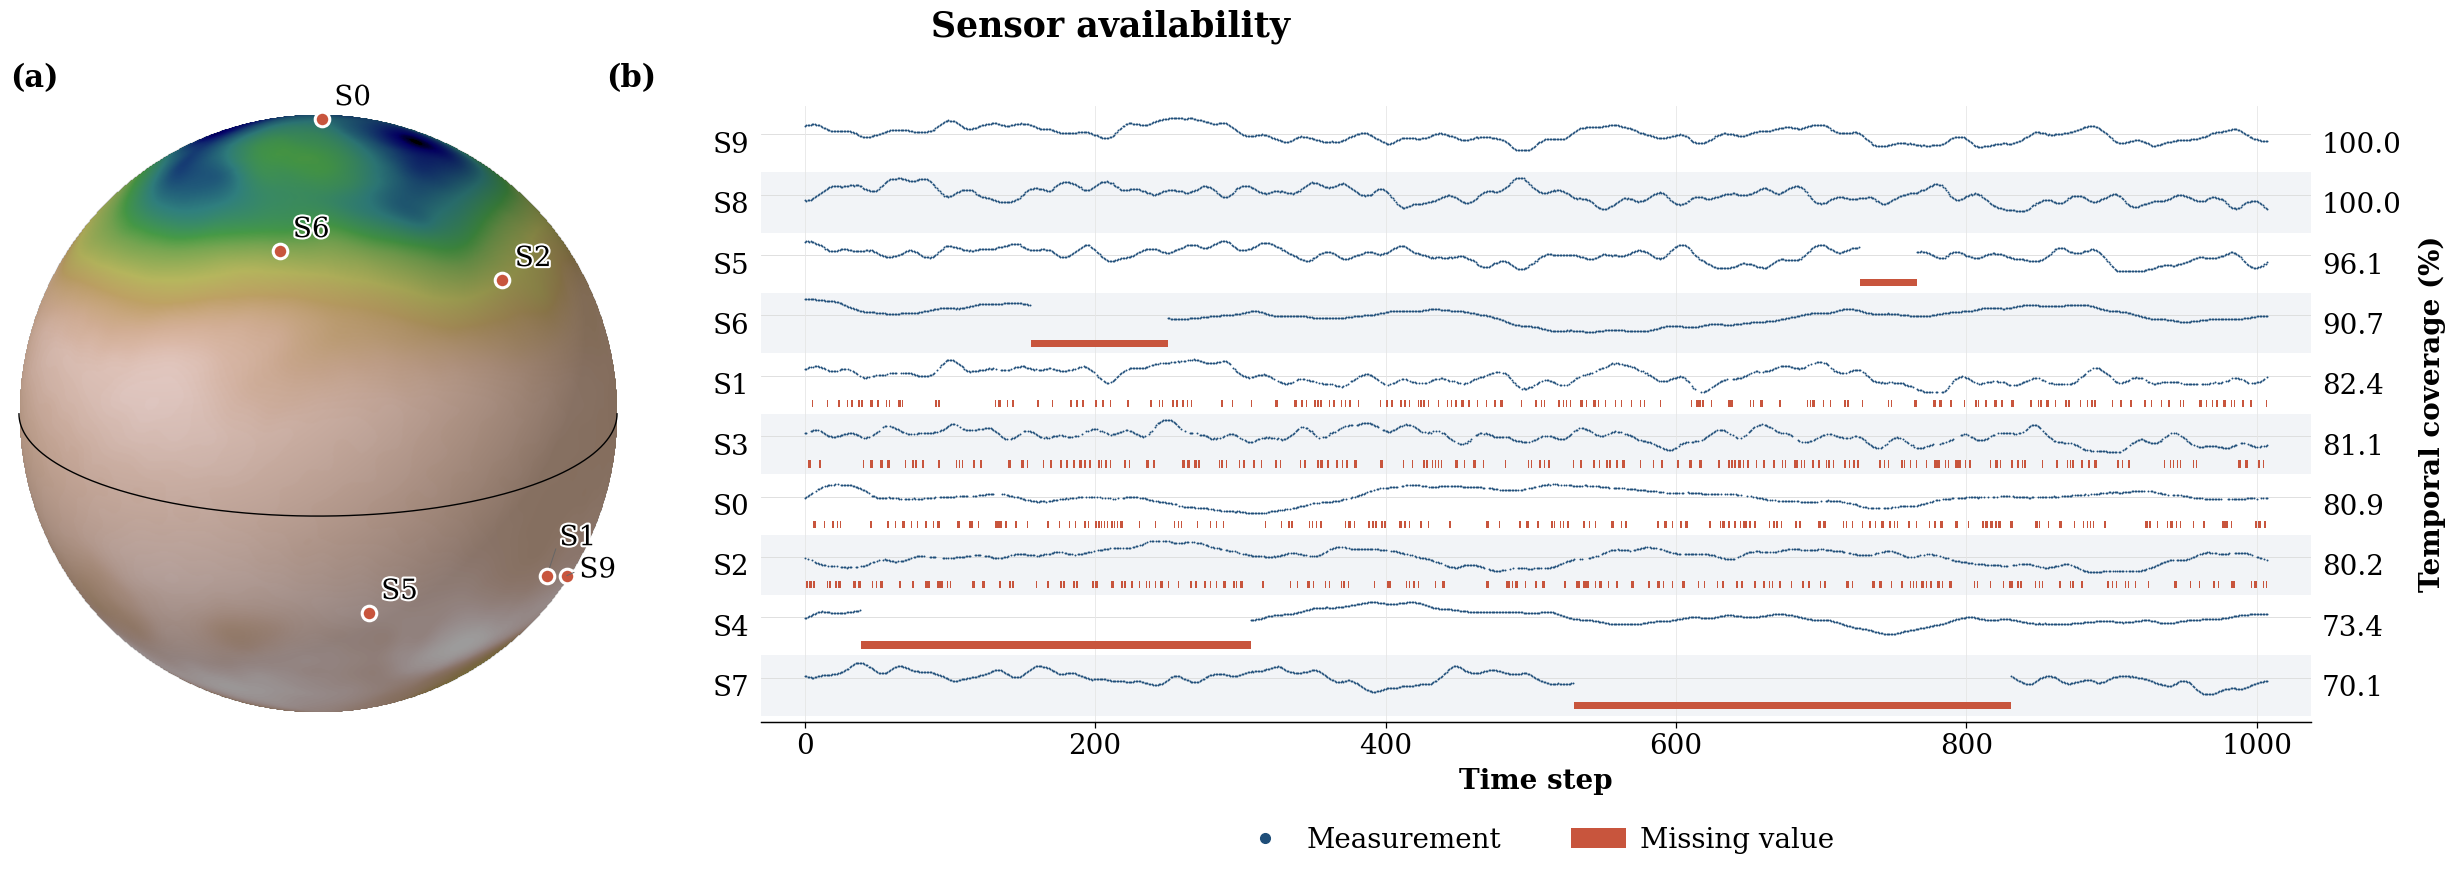

In [6]:
# ==================================================================
# RUN
# ==================================================================
def get_sensor_obs():
    """
    Build the objects needed by the plots from the notebook variables
    (sensors_data, sensors_coordinates, H).

    Cell 10 reshapes + shuffles sensors_data and H into (16, 63, ...) chunks.
    Here the shuffle is undone with `permutation`, so the time axis is the
    original one (0 ... ntimes-1).

    Returns
    -------
    obs_list : list of SimpleNamespace(name, values, x, y)
    H0       : (Lx, Ly) height field at the first time step (map background)
    ntimes   : number of time steps
    """
    sd = sensors_data.detach().cpu().numpy() if hasattr(sensors_data, "detach") else np.asarray(sensors_data)

    if sd.ndim == 3:                                  # cell 10 has been run
        inv = np.argsort(permutation)                 # inverse of the shuffle
        H0 = H[inv[0], 0]                             # first snapshot of the original series
        sd = sd[inv].reshape(-1, sd.shape[-1])        # back to (ntimes, nsensors)
    else:                                             # cell 10 NOT run
        H0 = H[0]

    H0 = H0.detach().cpu().numpy() if hasattr(H0, "detach") else np.asarray(H0)
    H0 = H0.reshape(Lx, Ly)

    obs_list = [
        SimpleNamespace(
            name=f"S{i}",
            values=sd[:, i],
            x=float(sensors_coordinates[i, 1]),       # column index (longitude direction)
            y=float(sensors_coordinates[i, 0]),       # row index (colatitude direction)
        )
        for i in range(sd.shape[1])
    ]
    return obs_list, H0, sd.shape[0]

wllist, H0, ntimes_plot = get_sensor_obs()

fig, axs, cov = plot_overview_and_availability(
    wllist, H0, ntimes_plot,
    figsize=(30, 8),
    font_scale=1.0,
    width_ratios=(0.3, 0.7),
    wspace=0.1,
    panel_labels=True,
    title="Sensor availability",
    elev_deg=20.0,
    azim_deg=90.0,
    savepath="SWE_1_availability.png",
)

## Check -> USE ROM AS IN SHRED ROM

In [7]:
np.random.seed(42)  # For reproducibility

print("Sensors data shape:\t", sensors_data.shape)
print("H shape:\t\t", H.shape)
print("Utheta shape:\t\t", Utheta.shape)
print("Uphi shape:\t\t", Uphi.shape)

H = np.vstack((H, H))
H = H.reshape(16, -1, 131072)
Utheta = np.vstack((Utheta, Utheta))
Utheta = Utheta.reshape(16, -1, 131072)
Uphi = np.vstack((Uphi, Uphi))
Uphi = Uphi.reshape(16, -1, 131072)
sensors_data = np.vstack((sensors_data, sensors_data))
sensors_data = sensors_data.reshape(16, -1, 10)

permutation = np.random.permutation(sensors_data.shape[0])
sensors_data = sensors_data[permutation]
H = H[permutation]
Utheta = Utheta[permutation]
Uphi = Uphi[permutation]

print("\nSensors data shape:\t", sensors_data.shape)
print("H shape:\t\t", H.shape)  
print("Utheta shape:\t\t", Utheta.shape)
print("Uphi shape:\t\t", Uphi.shape)

Sensors data shape:	 torch.Size([1008, 10])
H shape:		 torch.Size([1008, 131072])
Utheta shape:		 torch.Size([1008, 131072])
Uphi shape:		 torch.Size([1008, 131072])

Sensors data shape:	 (16, 126, 10)
H shape:		 (16, 126, 131072)
Utheta shape:		 (16, 126, 131072)
Uphi shape:		 (16, 126, 131072)


In [8]:
ERRORS = []

# DataManager
LAGS = 100

TRAIN_SIZE = 0.8        # percentage of data used for training 
VAL_SIZE = 0.1          # percentage of data used for validation
TEST_SIZE = 0.1         # percentage of data used for testing

COMPRESS = 100

# Training
OPTIMIZER = "AdamW"     # optimizer to use
LEARNING_RATE = 5e-4    # learning rate for training
NUM_EPOCHS = 200        # maximum number of epochs for training
LR_SCHEDULER = "CosineAnnealingLR"      # learning rate scheduler to use
SCHEDULER_STEP_SIZE = NUM_EPOCHS        # step size for learning rate scheduler (if applicable)

BATCH_SIZE = 32         # batch size for training
PATIENCE = 80           # number of epochs with no improvement on validation loss before stopping training
VERBOSE_TRAIN = True

# Architecture
ENCODER_DEPTH = 1               # number of encoder layers
HIDDEN_SIZE = 32                # hidden size for encoder and decoder layers
N_HEADS = 4                     # number of attention heads (if using a transformer-based architecture)
DIM_FEEDFORWARD = 48            # dimension of feedforward network in transformer (if using a transformer-based architecture)
DECODER = "cnn"                 # type of decoder to use (mpl or cnn)   
DECODER_HIDDEN_SIZES = [64]    # hidden sizes for decoder layers 
DROPOUT = 0.1                   # dropout rate for encoder and decoder layers
MASKING_TYPE = "mask_data"      # type of masking to apply to inputs during training (mask_data, mask_data_random, etc.)

## (T.3.A): Masking

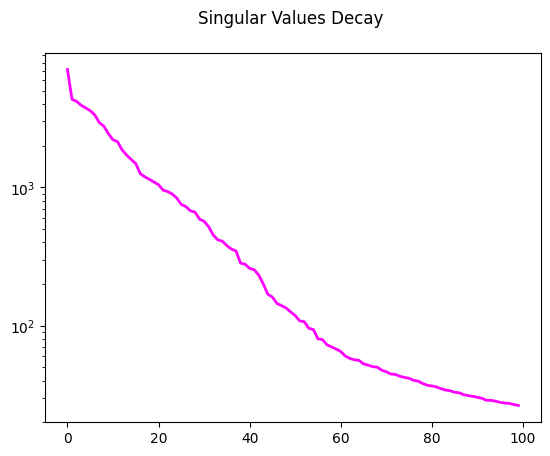

Residual energy of Surface elevation after keeping 100 modes: 0.0299 %


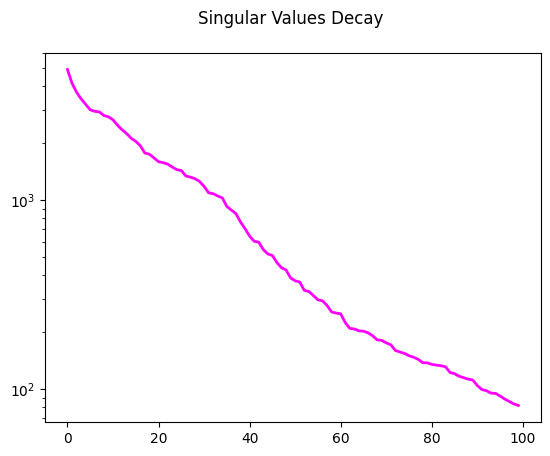

Residual energy of U theta after keeping 100 modes: 0.0851 %


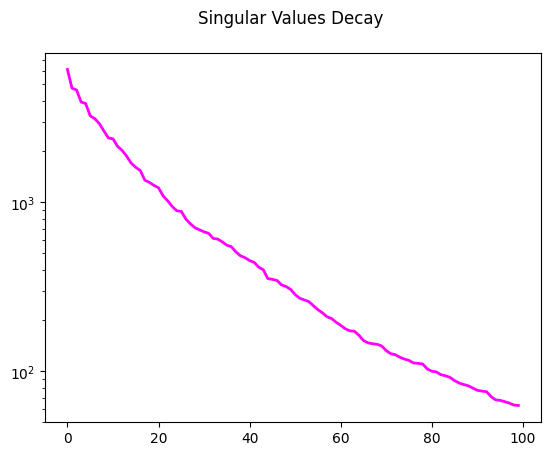

Residual energy of U phi after keeping 100 modes: 0.0452 %

Datasets: ['Surface elevation', 'U theta', 'U phi']

Number of nan values in sensor measurements after masking: 2926

Data shapes after preparation:
Train:	 torch.Size([1512, 100, 10]) -> torch.Size([1512, 300])
Val:	 torch.Size([252, 100, 10]) -> torch.Size([252, 300])
Test:	 torch.Size([252, 100, 10]) -> torch.Size([252, 300])

Input shape for the model: 10
Output shape for the model: 300


In [9]:
# Data manager
manager = ROMDataManager(lags=LAGS, train_size=TRAIN_SIZE, val_size=VAL_SIZE, test_size=TEST_SIZE)
# add data to manager
manager.add_data(H, id="Surface elevation", compress=COMPRESS, measurements=sensors_data, verbose=True)
manager.add_data(Utheta, id="U theta", compress=COMPRESS, verbose=True)
manager.add_data(Uphi, id="U phi", compress=COMPRESS, verbose=True)
# prepare datasets
train_dataset, val_dataset, test_dataset = manager.prepare(verbose=True, masking_type=MASKING_TYPE)

# network input and output shapes
nn_input_shape = train_dataset.X.shape[-1]
nn_output_shape = train_dataset.Y.shape[-1]
print("\nInput shape for the model:", nn_input_shape)
print("Output shape for the model:", nn_output_shape)

## (T.3.G): Masking x2 channels + MHSA learned

In [11]:
# mSHRED TRAINING
model_args = dict(
    # Encoder
    encoder="transformer_learned_mask", encoder_depth=ENCODER_DEPTH, input_size=nn_input_shape, n_heads=N_HEADS,
    dim_feedforward=DIM_FEEDFORWARD, hidden_size=HIDDEN_SIZE, input_length=LAGS, double_channels=True,
    # Decoder
    decoder=DECODER, decoder_hidden_sizes=DECODER_HIDDEN_SIZES, output_size=nn_output_shape, dropout=DROPOUT, 
 )
mshred = mSHRED(args=model_args).to(device)

# if model has been trained before, load the weights
if Path("model/mshred_model_weights.pth").exists():
    mshred.load_state_dict(torch.load("model/mshred_model_weights.pth"))
else:
    # Use cosine annealing LR schedule
    train_errors, valid_errors = fit(
        mshred, train_dataset, val_dataset,
        optimizer=OPTIMIZER, lr=LEARNING_RATE, num_epochs=NUM_EPOCHS, patience=PATIENCE, verbose=VERBOSE_TRAIN,
        lr_scheduler=LR_SCHEDULER, scheduler_step_size=SCHEDULER_STEP_SIZE,
        masking_type=MASKING_TYPE,
    )

    # Save the model weights (create the directory if it doesn't exist)
    Path("model").mkdir(parents=True, exist_ok=True)
    torch.save(mshred.state_dict(), "model/mshred_model_weights.pth")



In [12]:
# mSHRED RECONSTRUCTION
engine = SHREDEngine(manager, mshred)
test_reconstruction = engine.sensor_to_reconstruction_dataset(test_dataset)

In [13]:
test_reconstruction["Surface elevation"].shape, test_reconstruction["U theta"].shape, test_reconstruction["U phi"].shape

((252, 131072), (252, 131072), (252, 131072))

In [14]:
H[-3:-1].reshape(-1, Lx*Ly).shape, Utheta[-3:-1].reshape(-1, Lx*Ly).shape, Uphi[-3:-1].reshape(-1, Lx*Ly).shape

((252, 131072), (252, 131072), (252, 131072))

Saved plot: /home/matteo/Documents/Masked-SHRED/Notebooks/SWE/SWE_2_reconstruction.png


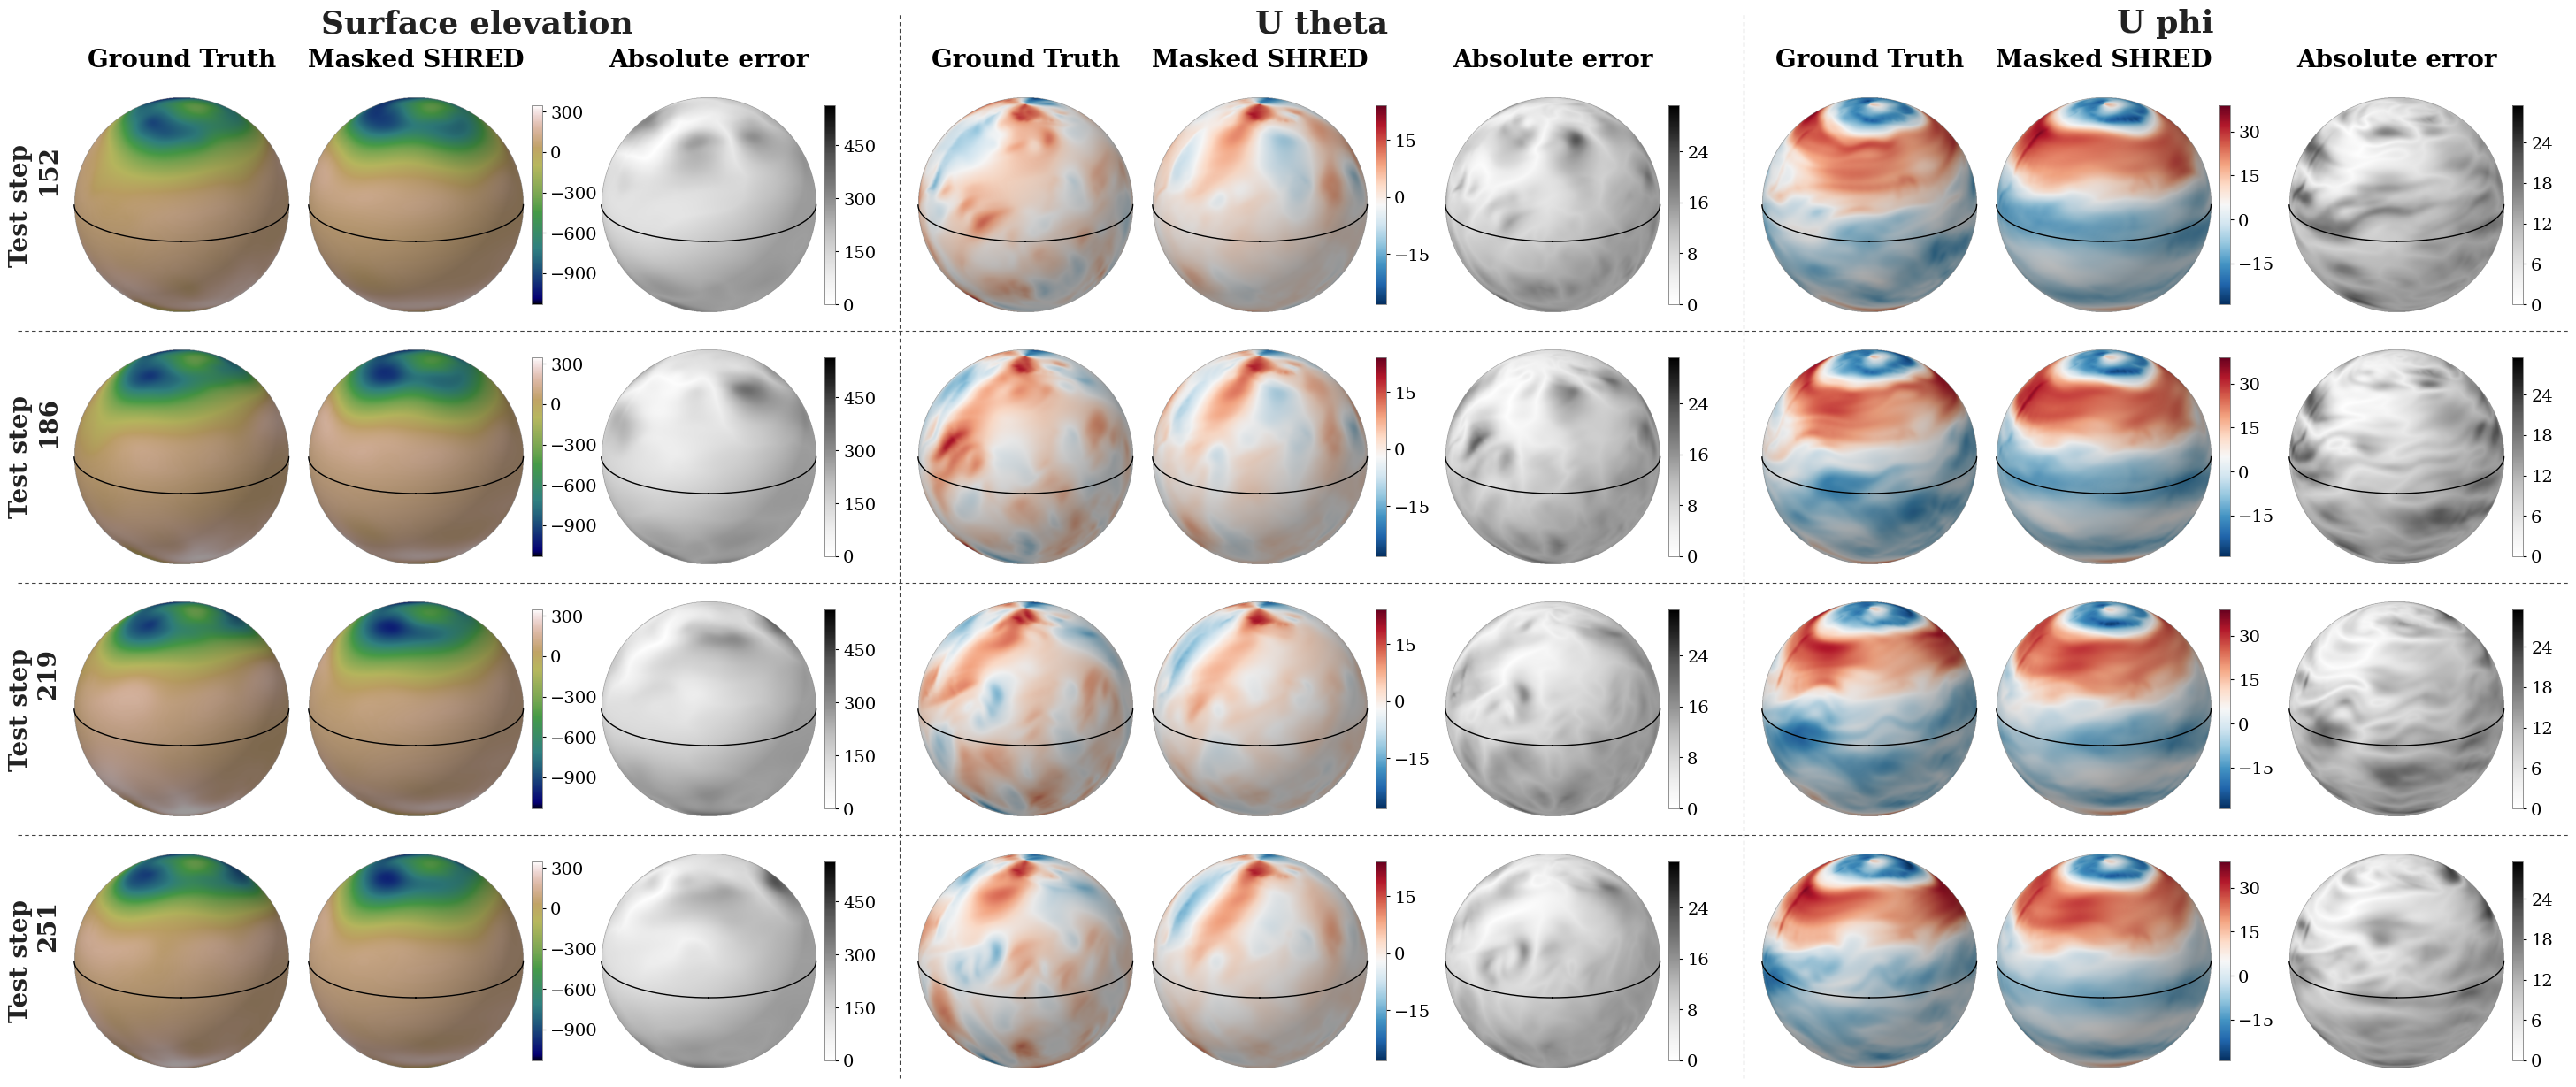

In [16]:
# ground truth for the *test* split, same order as test_reconstruction
ground_truth = {
    "Surface elevation": H[-3:-1].reshape(-1, Lx*Ly),
    "U theta":           Utheta[-3:-1].reshape(-1, Lx*Ly),
    "U phi":             Uphi[-3:-1].reshape(-1, Lx*Ly)
}

plot_shred_reconstruction_multi(
    test_reconstruction, ground_truth, grid_shape=(Lx, Ly),
    time_idxs=(-100, -66, -33, -1), title="SWE_2_reconstruction",
    elev_deg=20.0, azim_deg=0.0, map_height=2.5, 
)